In [1]:
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [2]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [3]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [4]:
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

In [5]:
df.dropna(subset=['pickup_zone', 'dropoff_zone',
                  'pickup_borough', 'dropoff_borough'], inplace=True)

In [6]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [7]:
df['pickup'] = pd.to_datetime(df['pickup'])

NameError: name 'pd' is not defined

In [8]:
import pandas as pd

In [9]:
df['pickup'] = pd.to_datetime(df['pickup'])

In [10]:
df['pickup'].dtype

dtype('<M8[us]')

In [11]:
df = df.sort_values('pickup')

In [13]:
import matplotlib.pyplot as plt

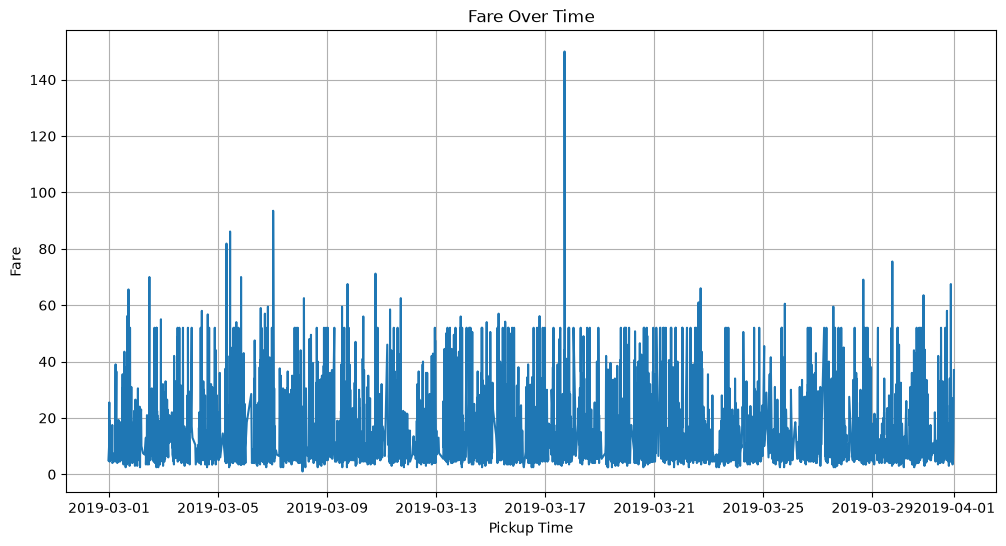

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(df['pickup'], df['fare'])

plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')

plt.grid(True)
plt.show()

In [15]:
borough_fare = df.groupby('pickup_borough')['fare'].sum()

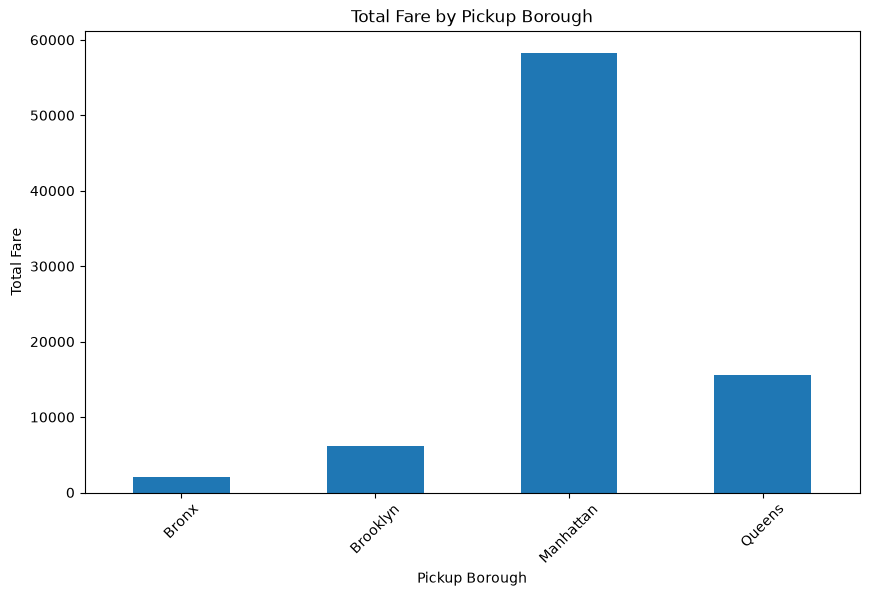

In [16]:
plt.figure(figsize=(10, 6))

borough_fare.plot(kind='bar')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.xticks(rotation=45)
plt.show()

In [17]:
payment_counts = df['payment'].value_counts()

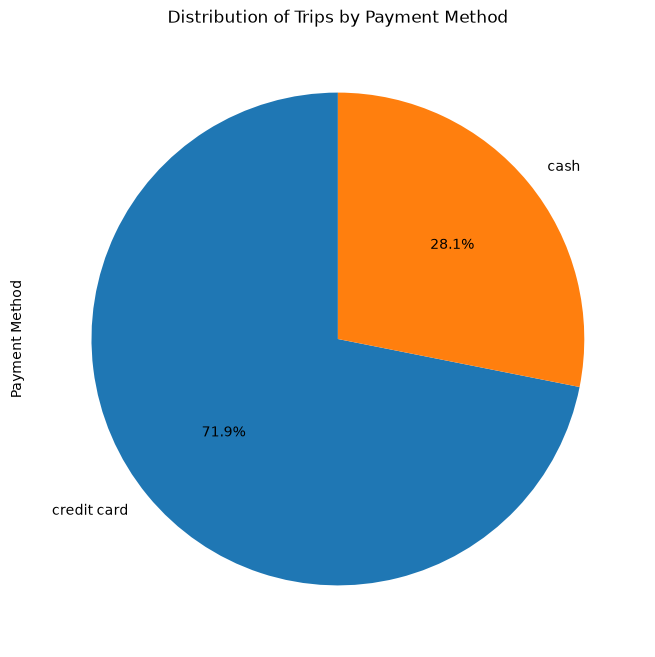

In [18]:
plt.figure(figsize=(8, 8))

payment_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')
plt.ylabel('Payment Method')

plt.show()

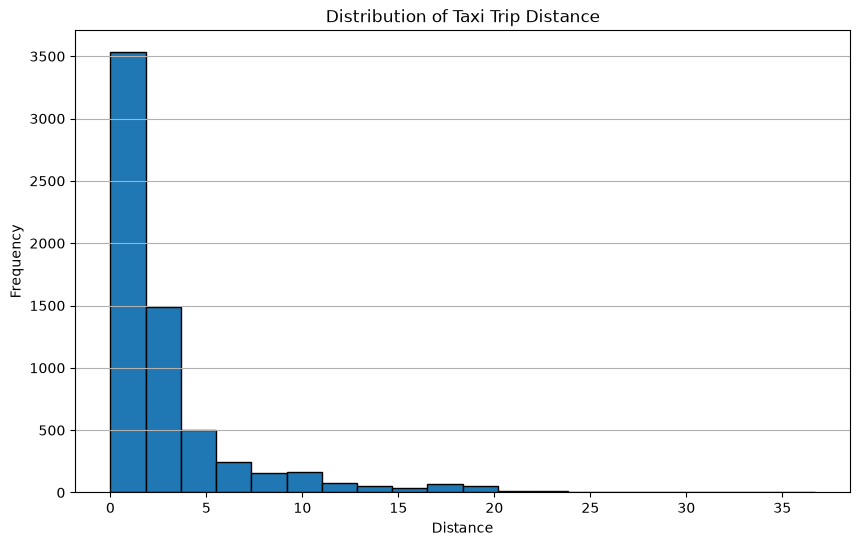

In [19]:
plt.figure(figsize=(10, 6))

plt.hist(df['distance'], bins=20, edgecolor='black')

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.grid(axis='y')
plt.show()

<Figure size 1000x600 with 0 Axes>

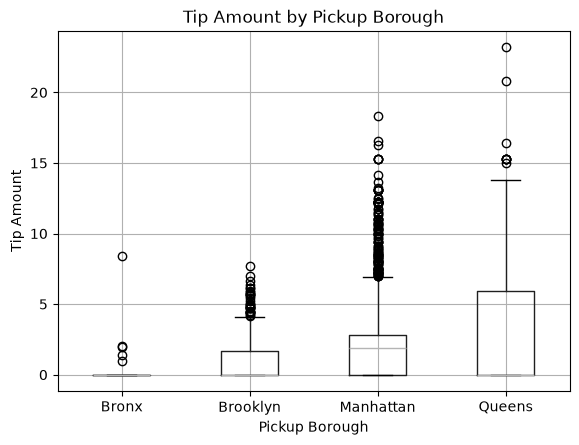

In [20]:
plt.figure(figsize=(10, 6))

df.boxplot(column='tip', by='pickup_borough')

plt.title('Tip Amount by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.show()

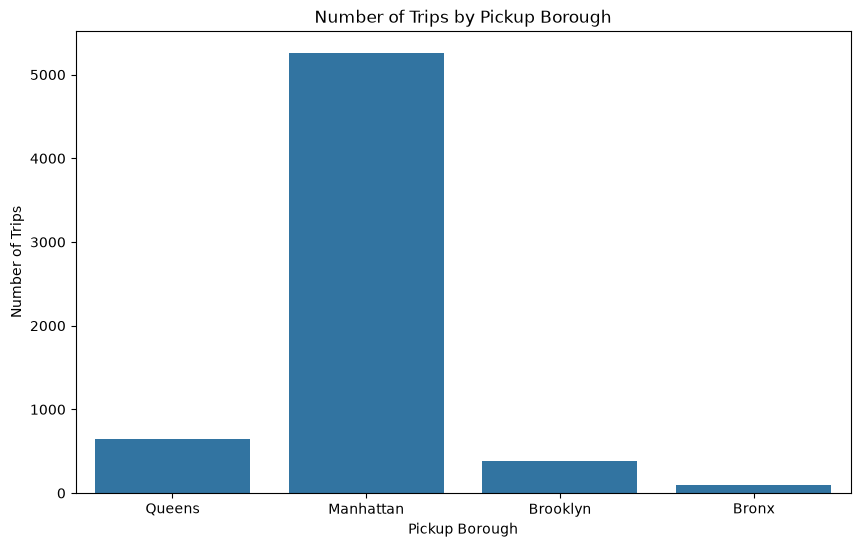

In [21]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.show()

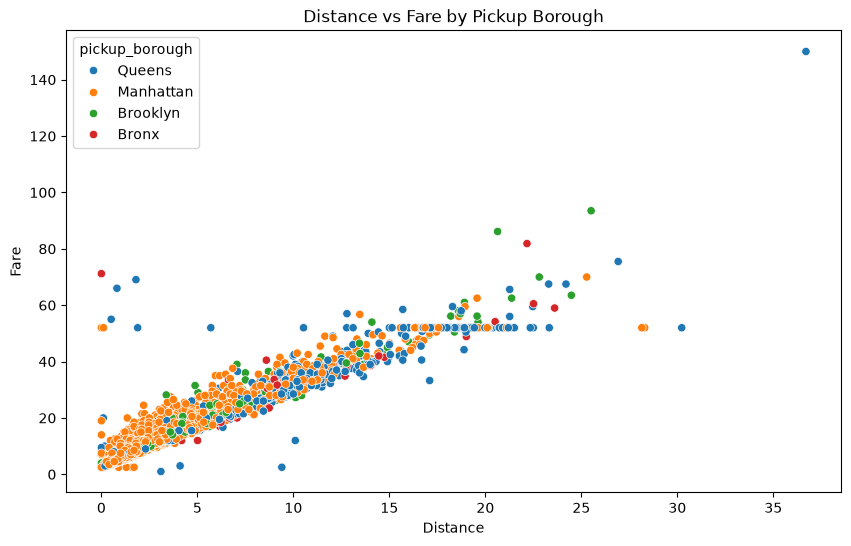

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')

plt.show()

In [23]:
corr = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()

corr

,distance,fare,tip,tolls,total
distance,1.000000,0.947021,0.475378,0.642899,0.928371
fare,0.947021,1.000000,0.485655,0.618184,0.972376
tip,0.475378,0.485655,1.000000,0.412787,0.649050
tolls,0.642899,0.618184,0.412787,1.000000,0.691506
total,0.928371,0.972376,0.649050,0.691506,1.000000


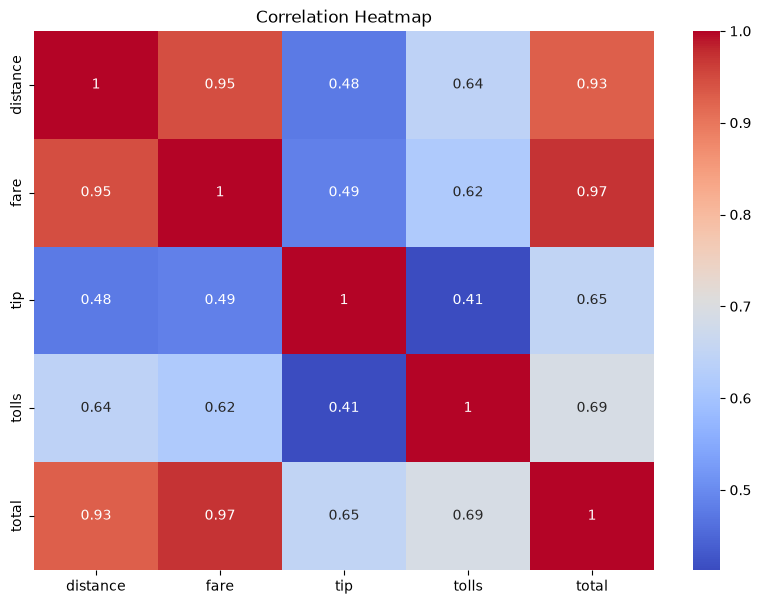

In [24]:
plt.figure(figsize=(10, 7))

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')

plt.show()

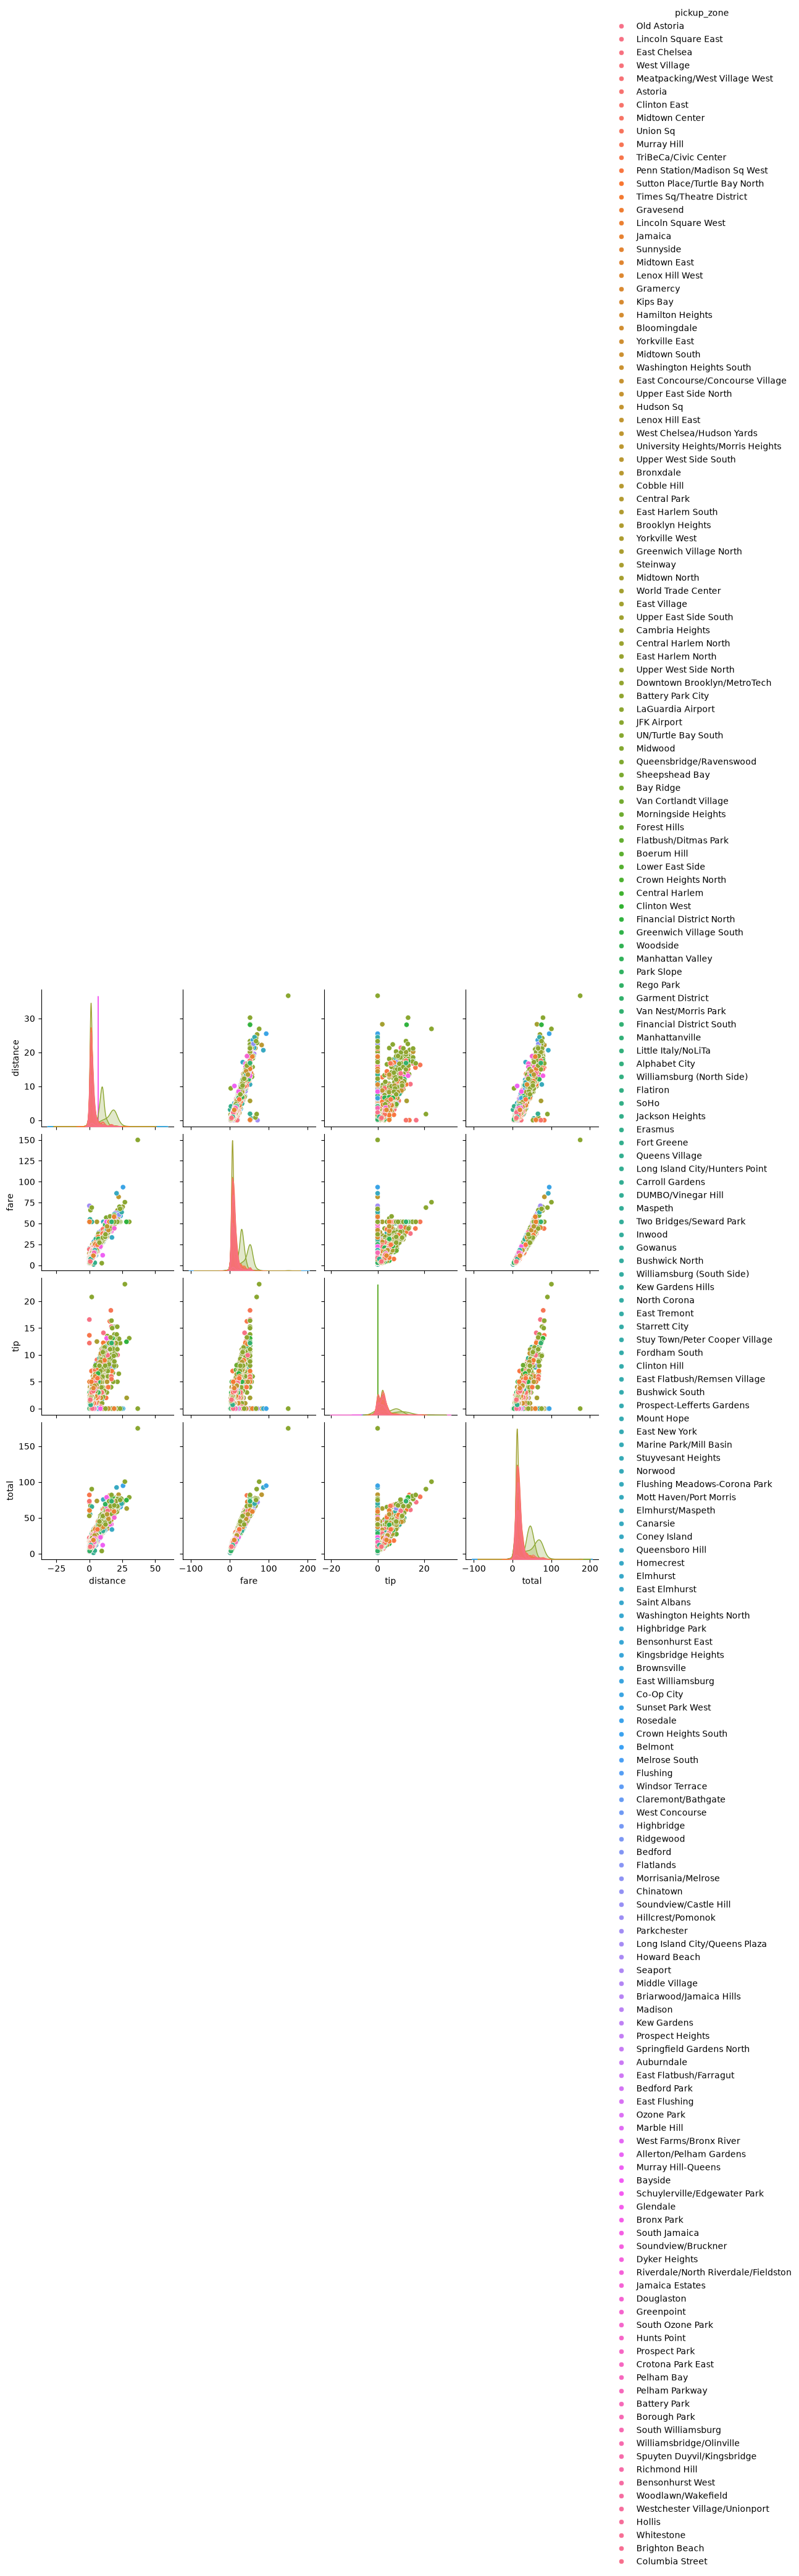

In [26]:
sns.pairplot(
    df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.show()

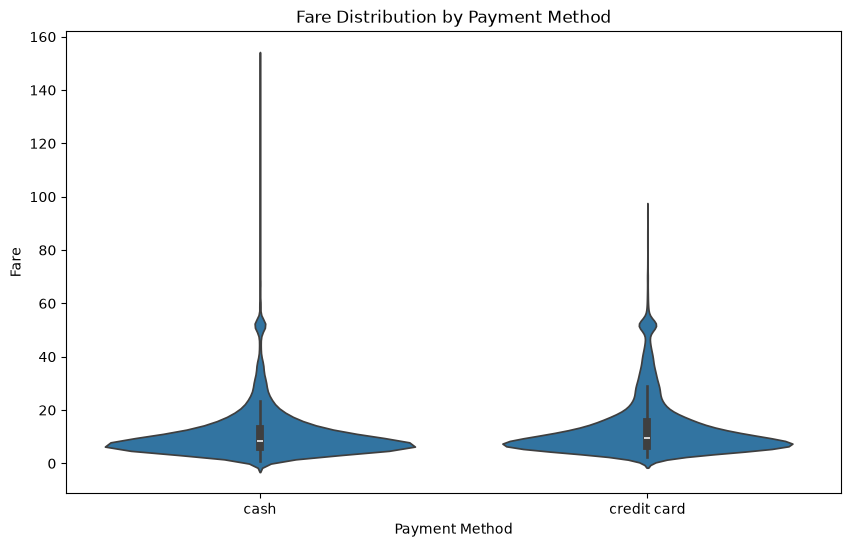

In [27]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

plt.show()